In [2]:
!pip -q install kagglehub

import kagglehub, shutil, os

src = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Downloaded to:", src)

# Baaqi cells 'ham/' folder expect karte hain, isliye copy kar do
if os.path.exists('ham'): shutil.rmtree('ham')
shutil.copytree(src, 'ham')

# Quick check
!ls ham
!ls ham | head

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Downloaded to: /kaggle/input/skin-cancer-mnist-ham10000
ham10000_images_part_1	HAM10000_images_part_2	hmnist_28_28_RGB.csv
HAM10000_images_part_1	HAM10000_metadata.csv	hmnist_8_8_L.csv
ham10000_images_part_2	hmnist_28_28_L.csv	hmnist_8_8_RGB.csv
ham10000_images_part_1
HAM10000_images_part_1
ham10000_images_part_2
HAM10000_images_part_2
HAM10000_metadata.csv
hmnist_28_28_L.csv
hmnist_28_28_RGB.csv
hmnist_8_8_L.csv
hmnist_8_8_RGB.csv


In [3]:
import os, glob, random, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.utils import make_grid

dev = 'cuda'
assert torch.cuda.is_available(), "GPU on karo: Runtime > Change runtime type"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

IMG_GAN = 64      # GAN image size
IMG_CLS = 128     # classifier input size (64 se upsample)

In [4]:
meta = pd.read_csv(glob.glob('ham/**/HAM10000_metadata.csv', recursive=True)[0])
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob('ham/**/*.jpg', recursive=True)}
meta['path'] = meta.image_id.map(paths)
assert meta.path.notna().all()
meta['y'] = (meta.dx == 'mel').astype(int)      # 1 = melanoma, 0 = baaqi sab

print(meta.dx.value_counts())
print("Unique lesions:", meta.lesion_id.nunique(), "| Images:", len(meta))

def load(p):
    im = Image.open(p).convert('RGB')
    w, h = im.size; s = min(w, h)
    l, t = (w - s)//2, (h - s)//2
    im = im.crop((l, t, l+s, t+s)).resize((IMG_GAN, IMG_GAN), Image.BILINEAR)  # center crop, aspect ratio bacha ke
    return np.asarray(im)

X = np.stack([load(p) for p in tqdm(meta.path)])   # (N,64,64,3) uint8
np.save('X64.npy', X)
print(X.shape)

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
Unique lesions: 7470 | Images: 10015


  0%|          | 0/10015 [00:00<?, ?it/s]

(10015, 64, 64, 3)


In [5]:
y = meta.y.values
g = meta.lesion_id.values

# 1/6 test
sg = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
trval_idx, test_idx = next(sg.split(X, y, g))
# baaqi mein se 1/6 validation
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_i, va_i = next(sg2.split(X[trval_idx], y[trval_idx], g[trval_idx]))
train_idx, val_idx = trval_idx[tr_i], trval_idx[va_i]

# LEAKAGE CHECK: koi lesion do splits mein nahi hona chahiye
L = lambda idx: set(g[idx])
assert not (L(train_idx) & L(val_idx)) and not (L(train_idx) & L(test_idx)) and not (L(val_idx) & L(test_idx))
print("No lesion_id overlap")

for n, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    print(f"{n}: {len(idx)} images, {y[idx].sum()} melanoma ({y[idx].mean()*100:.1f}%)")

# GPU tensors (uint8, N,3,H,W)
Xt = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous().to(dev)
yt = torch.from_numpy(y).float().to(dev)
X_train, y_train = Xt[train_idx], yt[train_idx]
X_val,   y_val   = Xt[val_idx],   yt[val_idx]
X_test,  y_test  = Xt[test_idx],  yt[test_idx]
y_val_np, y_test_np = y_val.cpu().numpy(), y_test.cpu().numpy()

No lesion_id overlap
train: 6966 images, 767 melanoma (11.0%)
val: 1374 images, 159 melanoma (11.6%)
test: 1675 images, 187 melanoma (11.2%)


In [6]:
nz = 100
SN = nn.utils.spectral_norm

class Gen(nn.Module):
    def __init__(s):
        super().__init__()
        def up(i, o): return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        s.net = nn.Sequential(
            nn.ConvTranspose2d(nz, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),
            *up(512, 256), *up(256, 128), *up(128, 64),
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())
    def forward(s, z): return s.net(z)

class Disc(nn.Module):
    def __init__(s):
        super().__init__()
        def blk(i, o): return [SN(nn.Conv2d(i, o, 4, 2, 1)), nn.LeakyReLU(0.2, True)]
        s.net = nn.Sequential(*blk(3, 64), *blk(64, 128), *blk(128, 256), *blk(256, 512),
                              SN(nn.Conv2d(512, 1, 4, 1, 0)))
    def forward(s, x): return s.net(x).view(-1)

def aug_d(x):
    m = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    x = torch.where(m, x.flip(3), x)
    m = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    return torch.where(m, x.flip(2), x)

mel_train = X_train[y_train == 1]
print("GAN training images (train melanoma only):", len(mel_train))
real_all = mel_train.float().div(127.5).sub(1)

set_seed(0)
G, D = Gen().to(dev), Disc().to(dev)
oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
z_fixed = torch.randn(64, nz, 1, 1, device=dev)
BS = 16                       # chhota batch => zyada iterations
done_epochs = 0
print(f"Setup done. ~{len(real_all)//BS} iterations per epoch. Ab Cell 5b chalao.")

GAN training images (train melanoma only): 767
Setup done. ~47 iterations per epoch. Ab Cell 5b chalao.


GAN training images (train melanoma only): 767
ep 100 | lossD 1.350 lossG 0.863


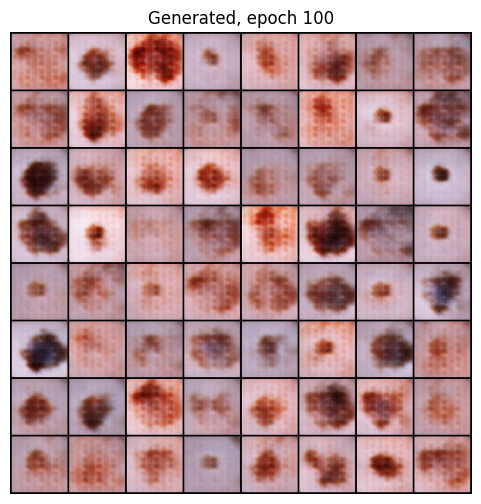

ep 200 | lossD 1.395 lossG 0.828


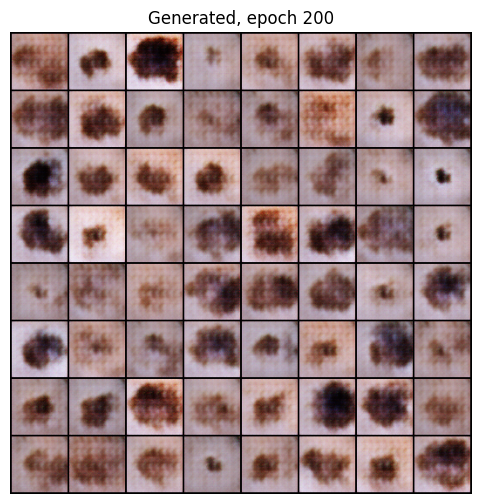

ep 300 | lossD 1.384 lossG 0.846


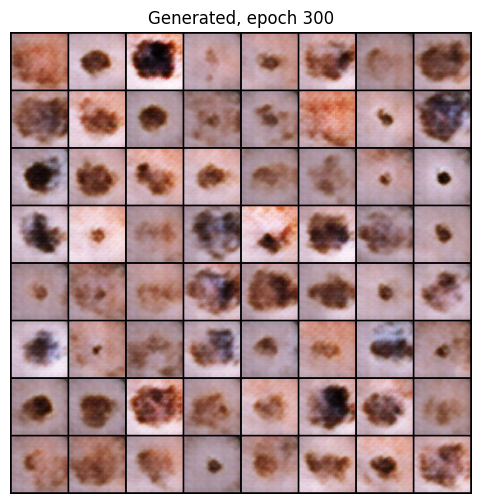

ep 400 | lossD 1.370 lossG 0.823


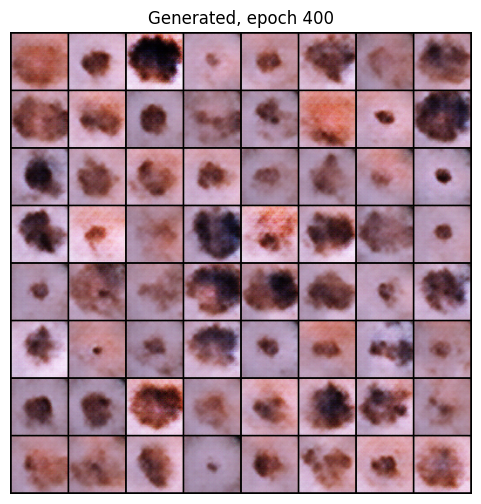

ep 500 | lossD 1.397 lossG 0.760


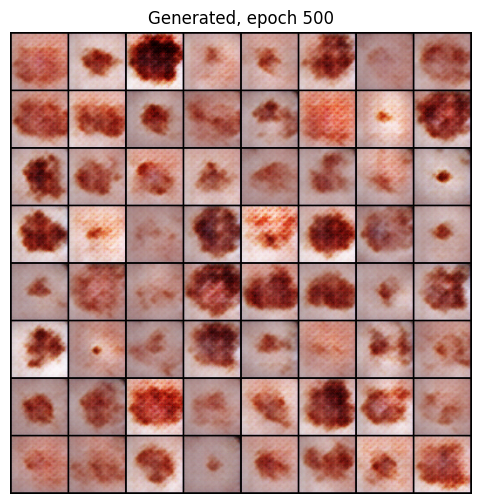

ep 600 | lossD 1.350 lossG 0.857


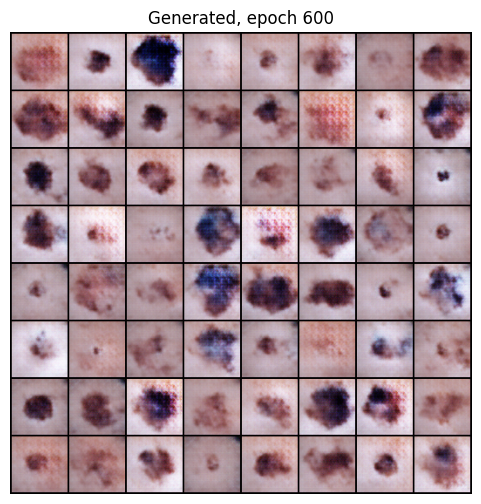

In [9]:
nz = 100
SN = nn.utils.spectral_norm

class Gen(nn.Module):
    def __init__(s):
        super().__init__()
        def up(i, o): return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        s.net = nn.Sequential(
            nn.ConvTranspose2d(nz, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),  # 4x4
            *up(512, 256), *up(256, 128), *up(128, 64),                                            # 32x32
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())                                         # 64x64
    def forward(s, z): return s.net(z)

class Disc(nn.Module):
    def __init__(s):
        super().__init__()
        def blk(i, o): return [SN(nn.Conv2d(i, o, 4, 2, 1)), nn.LeakyReLU(0.2, True)]
        s.net = nn.Sequential(*blk(3, 64), *blk(64, 128), *blk(128, 256), *blk(256, 512),
                              SN(nn.Conv2d(512, 1, 4, 1, 0)))
    def forward(s, x): return s.net(x).view(-1)

def aug_d(x):  # D ko overfit hone se bachane ke liye: real aur fake dono pe same flips
    m = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    x = torch.where(m, x.flip(3), x)
    m = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    return torch.where(m, x.flip(2), x)

mel_train = X_train[y_train == 1]
print("GAN training images (train melanoma only):", len(mel_train))
real_all = mel_train.float().div(127.5).sub(1)       # [-1, 1]

set_seed(0)
G, D = Gen().to(dev), Disc().to(dev)
oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
z_fixed = torch.randn(64, nz, 1, 1, device=dev)

GAN_EPOCHS, BS = 600, 64
for ep in range(1, GAN_EPOCHS + 1):
    perm = torch.randperm(len(real_all), device=dev)
    for i in range(0, len(perm) - BS + 1, BS):
        real = real_all[perm[i:i+BS]]
        z = torch.randn(BS, nz, 1, 1, device=dev)
        fake = G(z)
        # --- D step (label smoothing 0.9)
        lossD = bce(D(aug_d(real)), torch.full((BS,), 0.9, device=dev)) + \
                bce(D(aug_d(fake.detach())), torch.zeros(BS, device=dev))
        oD.zero_grad(); lossD.backward(); oD.step()
        # --- G step
        lossG = bce(D(aug_d(fake)), torch.ones(BS, device=dev))
        oG.zero_grad(); lossG.backward(); oG.step()
    if ep % 100 == 0:
        print(f"ep {ep} | lossD {lossD.item():.3f} lossG {lossG.item():.3f}")
        G.eval()
        with torch.no_grad(): s = G(z_fixed).cpu()
        G.train()
        plt.figure(figsize=(6, 6)); plt.axis('off'); plt.title(f"Generated, epoch {ep}")
        plt.imshow(make_grid((s + 1) / 2, nrow=8).permute(1, 2, 0).clamp(0, 1)); plt.show()

torch.save(G.state_dict(), 'G_mel.pt')

In [10]:
   from google.colab import files
   files.download('G_mel.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Synthetic: torch.Size([2301, 3, 64, 64])


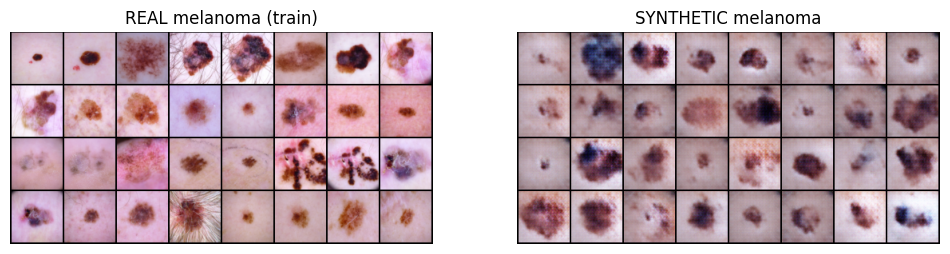

In [11]:
G.eval()
n_pos = int(y_train.sum().item())
N_SYN_MAX = 3 * n_pos
with torch.no_grad():
    syn = torch.cat([G(torch.randn(256, nz, 1, 1, device=dev)) for _ in range((N_SYN_MAX // 256) + 1)])[:N_SYN_MAX]
X_syn = ((syn + 1) * 127.5).round().clamp(0, 255).byte()        # uint8, (N,3,64,64)
print("Synthetic:", X_syn.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(make_grid(mel_train[:32].cpu().float() / 255, nrow=8).permute(1, 2, 0)); ax[0].set_title("REAL melanoma (train)")
ax[1].imshow(make_grid(X_syn[:32].cpu().float() / 255, nrow=8).permute(1, 2, 0)); ax[1].set_title("SYNTHETIC melanoma")
for a in ax: a.axis('off')
plt.savefig('real_vs_syn.png', dpi=150, bbox_inches='tight'); plt.show()

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def prep(xb, train):
    x = xb.float() / 255
    if train:                                   # simple GPU augmentation (sab methods mein same)
        if random.random() < 0.5: x = x.flip(3)
        if random.random() < 0.5: x = x.flip(2)
        x = torch.rot90(x, random.randint(0, 3), (2, 3))
        x = (x * (1 + 0.2 * (torch.rand(x.size(0), 1, 1, 1, device=dev) - 0.5))).clamp(0, 1)
    x = F.interpolate(x, size=IMG_CLS, mode='bilinear', align_corners=False)
    return (x - MEAN) / STD

@torch.no_grad()
def predict(model, Xs):
    model.eval(); out = []
    for i in range(0, len(Xs), 256):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(torch.sigmoid(model(prep(Xs[i:i+256], False)).float().squeeze(1)).cpu())
    return torch.cat(out).numpy()

def run(Xtr, ytr, seed, mode='plain', epochs=12, bs=64, lr=1e-4):
    set_seed(seed)
    model = resnet18(weights=ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(512, 1)
    model = model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = torch.amp.GradScaler()
    npos = ytr.sum().item(); nneg = len(ytr) - npos
    pw = torch.tensor([nneg / npos], device=dev) if mode == 'weighted' else None
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    sw = torch.where(ytr == 1, 0.5 / npos, 0.5 / nneg)   # oversample: 50/50 sampling
    best_auc, best_state = -1, None
    for ep in range(epochs):
        model.train()
        idx = torch.multinomial(sw, len(ytr), replacement=True) if mode == 'oversample' \
              else torch.randperm(len(ytr), device=dev)
        for i in range(0, len(idx) - bs + 1, bs):
            b = idx[i:i+bs]
            with torch.autocast('cuda', dtype=torch.float16):
                loss = crit(model(prep(Xtr[b], True)).squeeze(1), ytr[b])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        auc = roc_auc_score(y_val_np, predict(model, X_val))   # best epoch VALIDATION se chuno
        if auc > best_auc: best_auc, best_state = auc, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model

def evaluate(model):
    pv, pt = predict(model, X_val), predict(model, X_test)
    thr = np.quantile(pv[y_val_np == 0], 0.90)        # threshold VAL se: 90% specificity
    return dict(
        auroc=roc_auc_score(y_test_np, pt),
        auprc=average_precision_score(y_test_np, pt),
        sens_at_spec90=(pt[y_test_np == 1] > thr).mean(),
        spec_at_thr=(pt[y_test_np == 0] <= thr).mean(),
        sens_at_0p5=(pt[y_test_np == 1] > 0.5).mean(),
    ), pt

In [14]:
configs = {                       # name: (mode, synthetic multiplier)
    'baseline':       ('plain', 0),
    'class_weighted': ('weighted', 0),
    'oversample':     ('oversample', 0),
    'gan_1x':         ('plain', 1),
    'gan_3x':         ('plain', 3),
}
SEEDS = [0, 1, 2]
rows, test_probs = [], {}

for name, (mode, mult) in configs.items():
    for seed in SEEDS:
        Xtr, ytr = X_train, y_train
        if mult > 0:                                   # synthetic sirf TRAIN mein add hoti hai
            k = mult * n_pos
            Xtr = torch.cat([X_train, X_syn[:k]])
            ytr = torch.cat([y_train, torch.ones(k, device=dev)])
        model = run(Xtr, ytr, seed, mode)
        m, pt = evaluate(model)                        # evaluation sirf REAL test pe
        rows.append(dict(method=name, seed=seed, **m)); test_probs[(name, seed)] = pt
        print(name, seed, {k: round(v, 3) for k, v in m.items()})
        del model; torch.cuda.empty_cache()

res = pd.DataFrame(rows); res.to_csv('results_raw.csv', index=False)
summary = res.groupby('method').agg(['mean', 'std']).drop(columns='seed').round(3)
summary = summary.loc[list(configs)]
print(summary)
summary.to_csv('results_summary.csv')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 112MB/s]


baseline 0 {'auroc': np.float64(0.881), 'auprc': np.float64(0.532), 'sens_at_spec90': np.float64(0.578), 'spec_at_thr': np.float64(0.911), 'sens_at_0p5': np.float64(0.396)}
baseline 1 {'auroc': np.float64(0.884), 'auprc': np.float64(0.575), 'sens_at_spec90': np.float64(0.642), 'spec_at_thr': np.float64(0.902), 'sens_at_0p5': np.float64(0.358)}
baseline 2 {'auroc': np.float64(0.884), 'auprc': np.float64(0.479), 'sens_at_spec90': np.float64(0.61), 'spec_at_thr': np.float64(0.908), 'sens_at_0p5': np.float64(0.316)}
class_weighted 0 {'auroc': np.float64(0.865), 'auprc': np.float64(0.478), 'sens_at_spec90': np.float64(0.572), 'spec_at_thr': np.float64(0.909), 'sens_at_0p5': np.float64(0.727)}
class_weighted 1 {'auroc': np.float64(0.888), 'auprc': np.float64(0.561), 'sens_at_spec90': np.float64(0.695), 'spec_at_thr': np.float64(0.888), 'sens_at_0p5': np.float64(0.749)}
class_weighted 2 {'auroc': np.float64(0.902), 'auprc': np.float64(0.556), 'sens_at_spec90': np.float64(0.684), 'spec_at_thr'

AUROC(gan_1x) - AUROC(baseline): +0.013  95% CI [+0.001, +0.024]
AUROC(gan_3x) - AUROC(baseline): +0.015  95% CI [+0.003, +0.026]
AUROC(oversample) - AUROC(baseline): -0.002  95% CI [-0.017, +0.013]
AUROC(class_weighted) - AUROC(baseline): +0.002  95% CI [-0.009, +0.014]
AUROC(gan_1x) - AUROC(oversample): +0.014  95% CI [+0.002, +0.029]


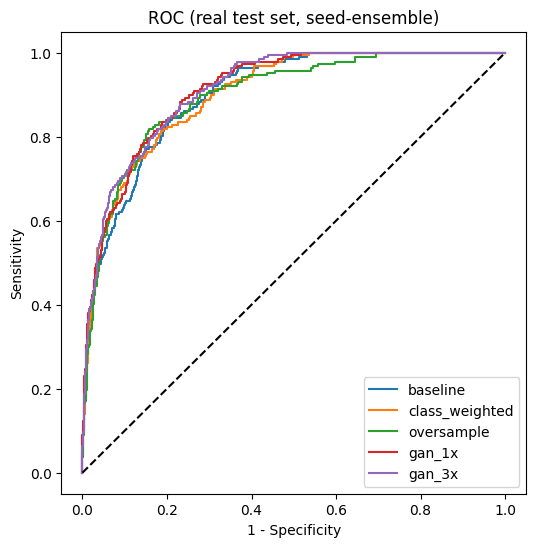

In [15]:
def ens(name):  # seeds ka average probability
    return np.mean([test_probs[(name, s)] for s in SEEDS], axis=0)

def boot_diff(a, b, n=1000, seed=0):
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y_test_np), len(y_test_np))
        if y_test_np[i].sum() in (0, len(i)): continue
        d.append(roc_auc_score(y_test_np[i], ens(a)[i]) - roc_auc_score(y_test_np[i], ens(b)[i]))
    return np.mean(d), np.percentile(d, [2.5, 97.5])

for cmp in ['gan_1x', 'gan_3x', 'oversample', 'class_weighted']:
    mu, ci = boot_diff(cmp, 'baseline')
    print(f"AUROC({cmp}) - AUROC(baseline): {mu:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")
mu, ci = boot_diff('gan_1x', 'oversample')
print(f"AUROC(gan_1x) - AUROC(oversample): {mu:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")
# Agar CI mein 0 shamil hai => farq statistically clear nahi.

from sklearn.metrics import roc_curve
plt.figure(figsize=(6, 6))
for n in configs:
    fpr, tpr, _ = roc_curve(y_test_np, ens(n)); plt.plot(fpr, tpr, label=n)
plt.plot([0, 1], [0, 1], 'k--'); plt.xlabel('1 - Specificity'); plt.ylabel('Sensitivity')
plt.legend(); plt.title('ROC (real test set, seed-ensemble)')
plt.savefig('roc.png', dpi=150, bbox_inches='tight'); plt.show()

In [16]:
from google.colab import files
for f in ['results_raw.csv', 'results_summary.csv', 'real_vs_syn.png', 'roc.png', 'G_mel.pt']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>